# Pergunta 2.3: o modelo é bom? Como medir?

> **Pergunta do case:** use métricas apropriadas (RMSE, MAE, R², etc.) e interprete os resultados.

| Passo | Pergunta |
|---|---|
| 1 | Que métricas usar, e o que cada uma diz? |
| 2 | Quanto o modelo erra na validação cruzada? (A, B e as referências) |
| 3 | Ele decorou o treino? (treino × validação) |
| 4 | Onde ele erra? (resíduos e subgrupos) |
| 5 | Mais dados ajudariam? (curva de aprendizado) |
| 6 | O resultado depende do sorteio? (estabilidade) |
| 7 | **O teste final, usado uma única vez** |

Os passos 1 a 6 usam só o treino. O teste guardado desde a Parte 1 só aparece no passo 7.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict, learning_curve

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.avaliacao import dobras, metricas, validar
from src.features import ALVO, COLUNAS_A, COLUNAS_B, carregar_treino_teste

pd.set_option("display.width", 200)
AZUL, CINZA, CINZA_CLARO = "#2a78d6", "#52514e", "#b8b7b1"
CORES_PLATAFORMA = {"Meta": "#2a78d6", "TikTok": "#eb6834", "LinkedIn": "#1baf7a"}

treino, teste = carregar_treino_teste(RAIZ / "data/raw/klike_challenge_dataset.csv")
y = treino[ALVO]
# Os modelos escolhidos no notebook 2.2 (regressão linear), treinados com todo o treino
modelo_A, modelo_B = joblib.load(RAIZ / "models/modelo_A.joblib"), joblib.load(RAIZ / "models/modelo_B.joblib")
COLUNAS = {"A": COLUNAS_A, "B": COLUNAS_B}
MODELOS = {"A": modelo_A, "B": modelo_B}

## Passo 1: que métricas usar?

O enunciado cita RMSE, MAE e R², "etc.". Uso essas três e mais oito, porque cada uma responde a uma pergunta diferente. **Erro** = nota real − nota prevista.

| Métrica | O que é | Analogia / leitura |
|---|---|---|
| **MAE** | a média do tamanho dos erros | "em média, erro X pontos" |
| **RMSE** | raiz da média dos erros ao quadrado; pune mais os erros grandes | se RMSE ≫ MAE, há alguns erros grandes |
| **R²** | fração da variação da nota que o modelo explica (0 = nada, 1 = tudo) | 0,70 = explica 70% de por que uma nota é diferente da outra |
| **R² ajustado** | o R² descontado pelo número de colunas; usado no treino (passo 3) | nos dados que o modelo viu, o R² simples nunca cai quando se acrescenta coluna, mesmo inútil; o ajustado cai. Na validação e no teste o R² já é honesto |
| **Erro mediano** | o erro do meio, em ordem | não se deixa levar por poucos erros enormes |
| **Erro máximo** | o pior erro | o "pior caso" que o cliente pode ver |
| **MAPE** | erro médio em % da nota real | faz sentido aqui porque a nota vai de ~10 a ~99 (nunca 0) |
| **% dentro de ±5 e ±10 pontos** | quantas previsões ficam perto | a mais fácil de explicar ao marketing |
| **90% dos erros abaixo de** | o erro que só 10% das previsões passam | "em 9 de cada 10 vídeos, erro menos de X pontos" |
| **Spearman** | correlação entre a **ordem** prevista e a real | o Klike serve para **ordenar** criativos: o melhor vem antes? |
| **Acerto do top 20%** | dos 20% melhores criativos de verdade, quantos o modelo também põe entre os 20% melhores | "o modelo acha os campeões?" (ao acaso, acertaria 20%) |

A nota vai de 0 a 100, então toda previsão é **limitada a [0, 100]** antes de medir (o passo 2 mostra se isso muda algo).

## Passo 2: quanto o modelo erra na validação cruzada?

Para os gráficos e as métricas por criativo, preciso de **uma previsão para cada criativo do treino**, feita por um modelo que não o viu. O `cross_val_predict` faz isso: divide o treino em 5 partes (mesma proporção de redes em cada) e prevê cada parte com um modelo treinado nas outras 4.

In [2]:
cinco_partes = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(treino, treino["platform"]))
previsto = {conjunto: cross_val_predict(clone(MODELOS[conjunto]), treino[COLUNAS[conjunto]], y, cv=cinco_partes)
            for conjunto in MODELOS}
# Referências: média geral e média da plataforma, também aprendidas só nas outras 4 partes
previsto["média geral"], previsto["média da plataforma"] = np.zeros(len(y)), np.zeros(len(y))
for dentro, fora in cinco_partes:
    previsto["média geral"][fora] = y.iloc[dentro].mean()
    medias = y.iloc[dentro].groupby(treino["platform"].iloc[dentro]).mean()
    previsto["média da plataforma"][fora] = treino["platform"].iloc[fora].map(medias)

n_colunas = {conjunto: MODELOS[conjunto][:-1].transform(treino[COLUNAS[conjunto]].head()).shape[1] for conjunto in MODELOS}
validacao = pd.DataFrame({
    "Modelo A (pré-lançamento)": metricas(y, previsto["A"]),
    "Modelo B (completo)": metricas(y, previsto["B"]),
    "média geral": metricas(y, previsto["média geral"]),
    "média da plataforma": metricas(y, previsto["média da plataforma"]),
})
fora_do_intervalo = {c: int(((previsto[c] < 0) | (previsto[c] > 100)).sum()) for c in MODELOS}
print("Previsões fora de [0, 100]:", fora_do_intervalo)
melhora = (1 - validacao.loc["MAE", "Modelo A (pré-lançamento)"] / validacao.loc["MAE", "média geral"]) * 100
print(f"O Modelo A erra {melhora:.0f}% menos que a média geral; "
      f"a nota tem desvio de {y.std():.1f} pontos e o Modelo A erra {validacao.loc['MAE', 'Modelo A (pré-lançamento)']:.1f}")
validacao.round(2)

Previsões fora de [0, 100]: {'A': 0, 'B': 0}
O Modelo A erra 46% menos que a média geral; a nota tem desvio de 15.9 pontos e o Modelo A erra 6.9


,Modelo A (pré-lançamento),Modelo B (completo),média geral,média da plataforma
MAE,6.93,5.63,12.81,12.74
RMSE,8.67,7.07,15.86,15.83
R²,0.70,0.80,-0.00,0.00
erro mediano,5.96,4.61,11.37,11.28
erro máximo,33.27,24.34,49.61,45.10
MAPE (%),13.47,10.67,27.25,26.99
% dentro de ±5 pts,43.50,53.25,24.25,24.25
% dentro de ±10 pts,73.25,82.75,45.75,45.25
90% dos erros abaixo de,13.23,11.77,24.43,24.94
Spearman,0.83,0.90,-0.04,-0.00


**Lendo a tabela (validação cruzada, 400 criativos):**

- **Nenhuma previsão saiu de [0, 100]:** limitar não muda nada aqui; fica como proteção para dados novos.
- **Erro típico:** o Modelo A erra em média **6,9 pontos** (erro mediano 6,0), numa nota cujo desvio é 15,9. O RMSE (8,7) é um pouco maior que o MAE: há alguns erros grandes (o pior, 33 pontos), mas poucos.
- **Explica 70% da variação da nota** (R² 0,70) e erra **46% menos** que chutar a média (12,8). Saber só a plataforma não ajuda (12,7).
- **Para o marketing:** 73% das previsões ficam a até 10 pontos da nota real, e em 9 de cada 10 vídeos o erro fica abaixo de 13,2 pontos. O erro médio é 13,5% da nota.
- **Para ordenar criativos, que é o uso do Klike, ele vai bem:** Spearman de 0,83 entre a ordem prevista e a real, e acerta 68% dos 20% melhores criativos (o acaso acertaria 20%; a média da plataforma, 14%).
- **O Modelo B erra 5,6 pontos** (R² 0,80). A distância entre A e B (1,3 ponto) é o que só se descobre depois de postar: o criativo, sozinho, já explica a maior parte da nota.

## Passo 3: ele decorou o treino?

**Overfitting** é quando o modelo decora os exemplos em vez de aprender a regra, como um aluno que decora as respostas da lista e erra a prova. O sinal: erro muito menor no treino (dados que ele viu) do que na validação (dados que não viu).

In [3]:
no_treino = {c: metricas(y, MODELOS[c].predict(treino[COLUNAS[c]]), n_colunas[c]) for c in MODELOS}
decorou = pd.DataFrame({
    f"Modelo {c}": {"colunas": n_colunas[c], "MAE no treino": no_treino[c]["MAE"], "MAE na validação": metricas(y, previsto[c])["MAE"],
                    "R² no treino": no_treino[c]["R²"], "R² ajustado no treino": no_treino[c]["R² ajustado"],
                    "R² na validação": metricas(y, previsto[c])["R²"]}
    for c in MODELOS}).T
decorou["validação ÷ treino (MAE)"] = decorou["MAE na validação"] / decorou["MAE no treino"]
decorou.round(2)

,colunas,MAE no treino,MAE na validação,R² no treino,R² ajustado no treino,R² na validação,validação ÷ treino (MAE)
Modelo A,24.0,6.47,6.93,0.74,0.72,0.7,1.07
Modelo B,32.0,5.10,5.63,0.84,0.82,0.8,1.10


**Não decorou:** o erro na validação é só 7% maior que no treino (6,9 contra 6,5 pontos), e o R² cai de 0,74 para 0,70. Para comparar: uma diferença grande (por exemplo, o dobro) seria sinal de decoreba. O R² ajustado no treino (0,72) já antecipa parte dessa queda, porque desconta as 24 colunas.

## Passo 4: onde ele erra?

O **resíduo** é o erro de cada criativo (real − previsto). Três gráficos, cada um respondendo a uma pergunta:
- **histograma dos resíduos:** os erros ficam em volta de zero, sem um lado preferido?
- **resíduo × previsto:** o erro muda conforme a nota prevista? (um "funil" ou uma curva indicariam algo que o modelo não pegou)
- **previsto × real:** com a linha de 45° (previsão perfeita), os pontos ficam perto dela?

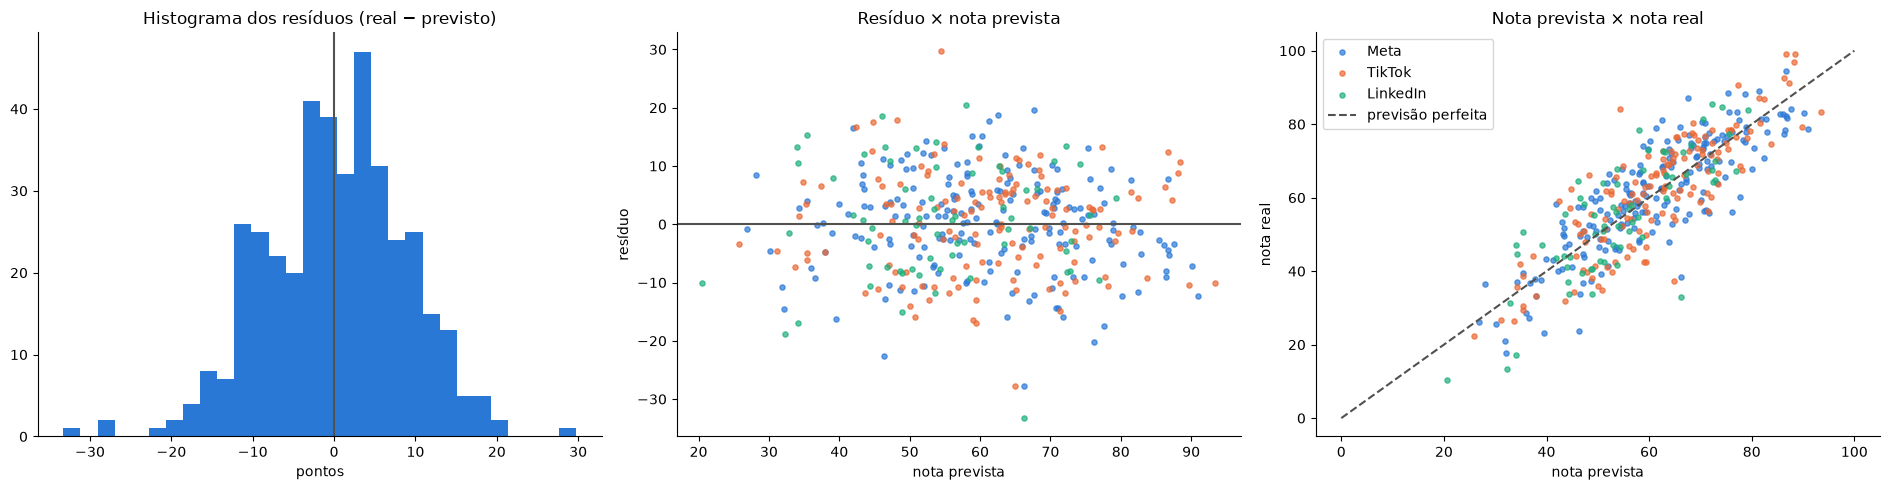

Resíduo médio: +0.18 pontos | correlação resíduo × previsto: -0.04


In [4]:
residuo = y - np.clip(previsto["A"], 0, 100)
fig, eixos = plt.subplots(1, 3, figsize=(19, 5))
eixos[0].hist(residuo, bins=30, color=AZUL)
eixos[0].axvline(0, color=CINZA)
eixos[0].set_title("Histograma dos resíduos (real − previsto)")
eixos[0].set_xlabel("pontos")
for rede, cor in CORES_PLATAFORMA.items():
    da_rede = treino["platform"] == rede
    eixos[1].scatter(previsto["A"][da_rede], residuo[da_rede], s=14, color=cor, alpha=0.7, label=rede)
    eixos[2].scatter(previsto["A"][da_rede], y[da_rede], s=14, color=cor, alpha=0.7, label=rede)
eixos[1].axhline(0, color=CINZA)
eixos[1].set_title("Resíduo × nota prevista")
eixos[1].set_xlabel("nota prevista")
eixos[1].set_ylabel("resíduo")
eixos[2].plot([0, 100], [0, 100], color=CINZA, linestyle="--", label="previsão perfeita")
eixos[2].set_title("Nota prevista × nota real")
eixos[2].set_xlabel("nota prevista")
eixos[2].set_ylabel("nota real")
eixos[2].legend()
for ax in eixos:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Resíduo médio: {residuo.mean():+.2f} pontos | correlação resíduo × previsto: {np.corrcoef(previsto['A'], residuo)[0, 1]:.2f}")

In [5]:
# Erro por subgrupo: onde o modelo vai pior?
treino_com_erro = treino.assign(erro=np.abs(residuo), faixa_nota=pd.qcut(y, 4, labels=["25% piores", "2º quarto", "3º quarto", "25% melhores"]))
por_grupo = pd.concat({coluna: treino_com_erro.groupby(coluna, observed=True)["erro"].agg(criativos="size", MAE="mean")
                       for coluna in ["platform", "category", "format", "objective", "faixa_nota"]})
por_grupo.round(2)

criativos   MAE
platform   LinkedIn             66  7.88
           Meta                193  6.58
           TikTok              141  6.96
category   App Install          68  6.14
           Branding             49  6.06
           E-commerce          137  7.07
           Lead Gen             73  7.49
           SaaS                 73  7.42
format     horizontal           90  6.85
           quadrado             92  6.98
           vertical            218  6.94
objective  app_install          37  5.83
           awareness            40  7.63
           conversions         129  7.16
           engagement           66  6.70
           traffic             128  6.90
faixa_nota 25% piores          100  8.20
           2º quarto           100  6.10
           3º quarto           101  6.18
           25% melhores         99  7.24

**Lendo os gráficos e a tabela:**

- **Os erros ficam em volta de zero** (resíduo médio +0,2 ponto), sem lado preferido, e **não mudam com a nota prevista** (correlação de −0,04): não há uma curva que o modelo deixou de pegar.
- **O modelo erra mais nos extremos:** 8,2 pontos nos 25% piores criativos e 7,2 nos 25% melhores, contra cerca de 6 no meio. É o efeito "puxar para a média" de todo modelo linear: as notas muito baixas ou muito altas têm algo que as colunas não contam (o gancho existe, mas é bom ou ruim?).
- **Por rede, o LinkedIn é o pior** (7,9 pontos, contra 6,6 no Meta): é a rede com menos criativos para aprender.
- **Por objetivo, awareness é o pior** (7,6) e app install o melhor (5,8). Categoria e formato variam pouco (6,1 a 7,5).

## Passo 5: mais dados ajudariam?

A **curva de aprendizado** treina o modelo com quantidades crescentes de dados (10% a 100% do treino de cada prova) e mede o erro no treino e na validação. Se as duas curvas já se encontraram e ficaram planas, mais dados do mesmo tipo ajudam pouco; se a validação ainda está caindo, ajudariam.

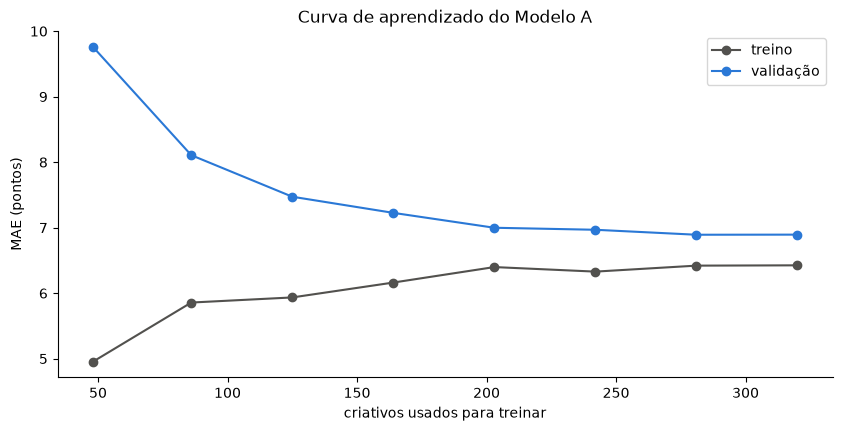

,criativos,MAE treino,MAE validação
0,48,4.95,9.76
1,86,5.86,8.11
2,125,5.93,7.47
3,164,6.16,7.23
4,203,6.40,7.00
5,242,6.33,6.97
6,281,6.42,6.89
7,320,6.43,6.89


In [6]:
cortes = dobras(treino)
tamanhos, erro_treino, erro_validacao = learning_curve(clone(modelo_A), treino[COLUNAS_A], y, cv=cortes,
                                                       train_sizes=np.linspace(0.15, 1, 8),
                                                       scoring="neg_mean_absolute_error")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tamanhos, -erro_treino.mean(axis=1), marker="o", color=CINZA, label="treino")
ax.plot(tamanhos, -erro_validacao.mean(axis=1), marker="o", color=AZUL, label="validação")
ax.set_xlabel("criativos usados para treinar")
ax.set_ylabel("MAE (pontos)")
ax.set_title("Curva de aprendizado do Modelo A")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()
pd.DataFrame({"criativos": tamanhos, "MAE treino": -erro_treino.mean(axis=1), "MAE validação": -erro_validacao.mean(axis=1)}).round(2)

**Mais dados ajudariam pouco:** o erro de validação cai rápido até cerca de 200 criativos (de 9,8 para 7,0 pontos) e depois fica quase plano (6,9 com 320). As duas curvas estão perto (6,4 no treino, 6,9 na validação). Para errar bem menos, o caminho não é mais criativos do mesmo tipo, e sim **colunas novas** que descrevam a qualidade do vídeo (por exemplo, se o gancho é bom, e não só se existe).

## Passo 6: o resultado depende do sorteio?

Repito a validação cruzada com 5 sementes diferentes (cada uma sorteia outras 15 provas). Só o treino entra: refazer a divisão treino/teste com outras sementes misturaria o teste com o treino, e ele deixaria de ser uma prova guardada.

In [7]:
estabilidade = pd.DataFrame({semente: validar(clone(modelo_A), treino[COLUNAS_A], y, dobras(treino, semente=semente)).mean()
                             for semente in [1, 7, 42, 123, 2024]}).T.rename_axis("semente")
print(f"MAE entre sementes: de {estabilidade['MAE'].min():.2f} a {estabilidade['MAE'].max():.2f} pontos")
estabilidade.round(3)

MAE entre sementes: de 6.89 a 7.00 pontos


,MAE,RMSE,R²
semente,,,
1,6.926,8.620,0.696
7,6.996,8.693,0.692
42,6.894,8.596,0.698
123,6.990,8.761,0.683
2024,6.951,8.669,0.697


**O resultado não depende do sorteio:** com 5 sementes diferentes, o MAE vai de 6,89 a 7,00 pontos e o R² de 0,68 a 0,70. A semente 42 não é um caso de sorte.

## Passo 7: o teste final (uma única vez)

Todas as escolhas estão feitas (colunas no 2.1, modelo e ajustes no 2.2). Agora, e só agora, os 100 criativos guardados desde a Parte 1. As referências usam as médias do treino.

In [8]:
y_teste = teste[ALVO]
medias_rede = y.groupby(treino["platform"]).mean()
no_teste = pd.DataFrame({
    "Modelo A (pré-lançamento)": metricas(y_teste, modelo_A.predict(teste[COLUNAS_A])),
    "Modelo B (completo)": metricas(y_teste, modelo_B.predict(teste[COLUNAS_B])),
    "média geral": metricas(y_teste, np.full(len(y_teste), y.mean())),
    "média da plataforma": metricas(y_teste, teste["platform"].map(medias_rede)),
})
lado_a_lado = pd.DataFrame({"A validação": validacao["Modelo A (pré-lançamento)"], "A teste": no_teste["Modelo A (pré-lançamento)"],
                            "B validação": validacao["Modelo B (completo)"], "B teste": no_teste["Modelo B (completo)"],
                            "média geral (teste)": no_teste["média geral"]})
mae_A, desvio_teste = no_teste.loc["MAE", "Modelo A (pré-lançamento)"], y_teste.std()
print(f"No teste, o Modelo A erra em média {mae_A:.1f} pontos numa nota cujo desvio é {desvio_teste:.1f}; "
      f"{no_teste.loc['% dentro de ±10 pts', 'Modelo A (pré-lançamento)']:.0f}% das previsões ficam a até 10 pontos da nota real, "
      f"e ele acerta {no_teste.loc['acerto do top 20% (%)', 'Modelo A (pré-lançamento)']:.0f}% dos 20% melhores criativos (o acaso daria 20%).")
lado_a_lado.round(2)

No teste, o Modelo A erra em média 6.7 pontos numa nota cujo desvio é 14.4; 74% das previsões ficam a até 10 pontos da nota real, e ele acerta 75% dos 20% melhores criativos (o acaso daria 20%).


,A validação,A teste,B validação,B teste,média geral (teste)
MAE,6.93,6.68,5.63,5.74,11.67
RMSE,8.67,8.38,7.07,7.01,14.37
R²,0.70,0.66,0.80,0.76,-0.00
erro mediano,5.96,5.96,4.61,5.17,10.36
erro máximo,33.27,21.81,24.34,18.60,32.29
MAPE (%),13.47,11.67,10.67,9.83,20.72
% dentro de ±5 pts,43.50,46.00,53.25,49.00,25.00
% dentro de ±10 pts,73.25,74.00,82.75,85.00,48.00
90% dos erros abaixo de,13.23,14.31,11.77,11.06,25.60
Spearman,0.83,0.81,0.90,0.86,NaN


**Lendo o teste:**

- **O Modelo A erra 6,7 pontos no teste** (R² 0,66), quase o mesmo da validação (6,9). A validação cruzada previu bem o que aconteceria com criativos novos.
- **O MAE caiu, mas o R² também caiu um pouco:** as notas do teste variam menos (desvio de 14,4, contra 15,9 no treino), e o R² mede o erro em relação a essa variação. Com menos variação para explicar, o mesmo erro vale um R² menor.
- **74% das previsões ficam a até 10 pontos**, e o modelo acerta 75% dos 20% melhores criativos (o acaso daria 20%). O Spearman é 0,81.
- **O Modelo B erra 5,7 pontos** (R² 0,76). Continua melhor que o A, mas a diferença é só de 1 ponto: o criativo explica a maior parte da nota antes de postar.
- **Chutar a média do treino erraria 11,7 pontos** no teste: o Modelo A erra 43% menos.

**Comparando com as referências preliminares** (validação cruzada 5×3, feitas antes deste trabalho):

| O quê | Referência preliminar | Aqui (validação, 15 provas) | Bateu? |
|---|---|---|---|
| Lineares, Modelo A | R² 0,69 a 0,70; MAE 6,9 | R² 0,70; MAE 6,9 | sim |
| Random Forest, A | R² 0,61; MAE 7,9 | R² 0,63; MAE 7,5 | quase; um pouco melhor aqui (ajuste e `n_boas_praticas`) |
| Rede neural, A | R² 0,36; MAE 9,7 | R² 0,57; MAE 8,1 | não; melhor aqui (tamanho ajustado), mas continua a pior |
| Chute pela média | MAE 12,8 | MAE 12,8 | sim |
| Lineares, Modelo B | R² 0,81; MAE 5,4 | R² 0,79; MAE 5,6 | quase; um pouco pior aqui (vazios preenchidos dentro do Pipeline e sem `category`) |
| Maiores efeitos (pontos) | gancho +17,7; texto médio × alto +15,5; rosto +11,6; legenda +8,2; CTA +7,5 | gancho +17,9; muito texto −15,1; rosto +11,5; legenda +8,1; CTA +7,5 | sim (diferenças menores que meio ponto) |


## Resposta à pergunta 2.3: que métricas usei, e o que elas dizem?

> 💡 **Conclusão**
>
> - **Usei 11 métricas**, além das três do enunciado (MAE, RMSE, R²): erro mediano e máximo, MAPE, % de previsões a até 5 e 10 pontos, "90% dos erros abaixo de", Spearman e acerto do top 20%. Cada uma responde a uma pergunta de um público diferente (banca, marketing, produto).
> - **Antes de postar, o modelo erra em média 6,7 pontos** em criativos que ele nunca viu (o teste), contra 11,7 de quem chuta a média. Em 3 de cada 4 vídeos, o erro fica abaixo de 10 pontos.
> - **Para ordenar criativos, que é o uso do Klike, ele é forte:** acha 75% dos 20% melhores criativos (o acaso acharia 20%).
> - **O que só se sabe depois de postar melhora pouco:** o modelo completo erra 5,7 pontos, só 1 a menos.
> - **Onde ele erra mais:** nos criativos muito bons ou muito ruins e no LinkedIn. Mais criativos do mesmo tipo ajudariam pouco; colunas que digam a qualidade do vídeo ajudariam mais.